# Coral acclimation: calibration and sensitivity, with the model in Simile

The model of Raharinirina, Acevedo-Trejos & Merico (2022), *Modelling the acclimation capacity of coral reefs to a warming ocean*, *PLoS Computational Biology* 18(5): e1010099 ([paper](https://doi.org/10.1371/journal.pcbi.1010099), [their code and data](https://github.com/systemsecologygroup/CoralZooxProjection)).

The model itself is a **Simile diagram** (`coral.json`, shown below with its equations; or open it in [Simile](https://robert-mue.github.io/model_gallery/models/coral/)). Everything done *with* the model here is ordinary Python:

1. one run, checked against the authors' published run;
2. **calibrating the speed of acclimation N** against observed coral cover, the paper's Fig 2;
3. **projections** to 2100 under three emission scenarios, beside the paper's headline numbers;
4. **sensitivity** of coral abundance to N and to ±25% in each of ten parameters, the paper's Figs 5 and 6.

**How the model runs.** `simile_run.Session` runs it in Simile's own engine, the one in the web app, in a hidden browser on this machine: a prototype, which needs the simile repository and Google Chrome. A run of 2146 simulated years (a 2000-year spin-up, then 1955 to 2100, eight steps a month) takes about half a second. The whole notebook takes about ten minutes.

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()                                   # examples/papers/coral
REPO = HERE.parents[2]                              # the simile repository
sys.path.insert(0, str(REPO / 'tools' / 'python'))
from simile_run import Session, SimileError, equations
from IPython.display import Image, Markdown, display

# The authors' repository (their temperatures, and their published runs), and
# the parameter files made from it: fetched and made once, beside this notebook.
THEIRS = HERE / 'their-code'
if not THEIRS.exists():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/systemsecologygroup/CoralZooxProjection', str(THEIRS)], check=True)
GEN = HERE / 'generated'
if not (GEN / 'coral.json').exists():
    subprocess.run([sys.executable, str(HERE / 'make_coral.py'), str(GEN), str(THEIRS)], check=True)
sys.path.insert(0, str(HERE))
from results_to_csv import load as load_theirs     # their numpy pickles, read safely

MODEL = json.loads((GEN / 'coral.json').read_text())
params = lambda reg, rcp: json.loads((GEN / f'coral-{reg}-{rcp}.parameters.json').read_text())
REGIONS = {'GBR': 'Great Barrier Reef', 'SEA': 'South East Asia', 'CAR': 'Caribbean'}
RCPS = {'RCP26': 'RCP 2.6', 'RCP45': 'RCP 4.5', 'RCP85': 'RCP 8.5'}
N_PAPER = {'GBR': 5.54e-13, 'SEA': 2.65e-13, 'CAR': 2.375e-13}   # the paper's estimates
SPINUP = 24012                                       # months before January 1955
year = lambda df: 1955 + df.index.values / 12        # model time (months from 1955) as years
SETTINGS = {'logEach': 1}                            # record every month
print('ready:', len(MODEL['nodes']), 'elements in the model;', ', '.join(f'{r} N={n:g}' for r, n in N_PAPER.items()))

ready: 57 elements in the model; GBR N=5.54e-13, SEA N=2.65e-13, CAR N=2.375e-13


## The model

The diagram and the equations below are read from the model itself, `coral.json`, as Simile holds it: drawn by Simile, not pasted in, so a change to the model changes them too.

Reading the diagram: the three boxes are the **stocks**, Coral (its abundance, cm²), Trait (the energy invested in the symbiosis) and Symbiont (cells), each changed by the **flows** into or out of it (the thick arrows with valves; a cloud is outside the model). The circles are **variables**, and a thin arrow says which values an equation uses. On the left, the temperature-limited growth rate `G_C`, a skewed normal curve of the temperature `T`; in the middle, the coral's fitness and its gradient, which drives acclimation; at the bottom right, bleaching.

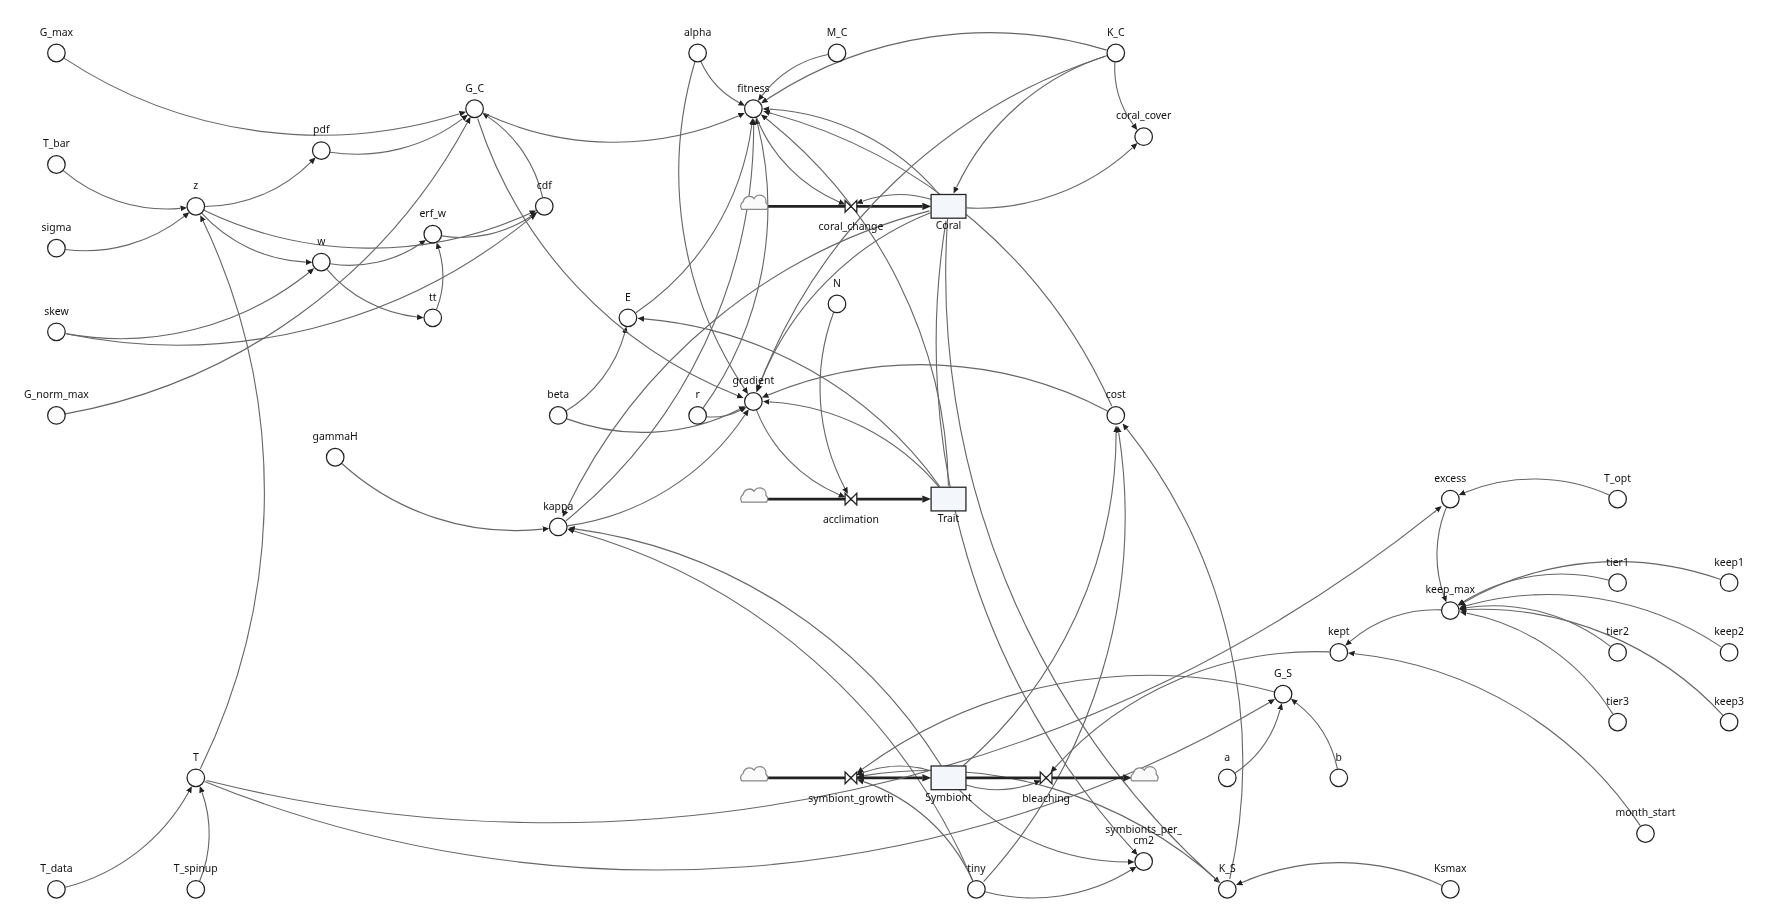

**Stocks**

| Stock | Starting value | Changed by |
|---|---|---|
| **Coral** | `0.75*K_C` | + coral_change |
| **Trait** | `0.0000005` | + acclimation |
| **Symbiont** | `0.001` | + symbiont_growth − bleaching |

**Flows**

| Flow | Rate |
|---|---|
| coral_change | `fitness*Coral` |
| acclimation | `N*gradient` |
| symbiont_growth | `G_S*(1-Symbiont/(K_S+tiny))*Symbiont` |
| bleaching | `(1-kept)*Symbiont/dt()` |

**Variables**

| Variable | Equation |
|---|---|
| T | `if time()<0 then T_spinup else T_data` |
| z | `(T-T_bar)/sigma` |
| pdf | `exp(-0.5*z*z)/sqrt(2*pi())` |
| w | `abs(skew*z)/sqrt(2)` |
| tt | `1/(1+0.3275911*w)` |
| erf_w | `1-(0.254829592*tt-0.284496736*tt^2+1.421413741*tt^3-1.453152027*tt^4+1.061405429*tt^5)*exp(-(w*w))` |
| cdf | `0.5*(1+sgn(skew*z)*erf_w)` |
| G_C | `G_max*pdf*cdf/G_norm_max` |
| K_S | `Ksmax*Coral` |
| kappa | `Symbiont/(gammaH*Coral+Symbiont+tiny)` |
| E | `1-exp(-beta*Trait)` |
| cost | `Symbiont/(K_S+tiny)` |
| fitness | `G_C*kappa*E*(1-Coral/K_C)-alpha*exp(r*Trait)*cost-M_C` |
| gradient | `G_C*beta*kappa*(1-Coral/K_C)*exp(-beta*Trait)-r*alpha*cost*exp(r*Trait)` |
| G_S | `a*exp(b*T)` |
| excess | `T-T_opt` |
| keep_max | `if excess>=tier3 then keep3 elseif excess>=tier2 then keep2 elseif excess>=tier1 then keep1 else 1.0` |
| month_start | `abs(time()-round(time()))<dt()/2` |
| kept | `if month_start and keep_max<1.0 then rand_var(0.05,keep_max) else 1.0` |
| coral_cover | `100*Coral/K_C` |
| symbionts_per_cm2 | `Symbiont/(Coral+tiny)` |

**Constants**

| Constant | Value |
|---|---|
| G_max | `0.8333333333333334` |
| a | `0.08973333333333333` |
| b | `0.0633` |
| alpha | `0.001` |
| M_C | `0.0008333333333333334` |
| Ksmax | `3000000` |
| beta | `1200` |
| gammaH | `1000000` |
| r | `12000` |
| tiny | `0.01` |

**Parameters** (default values; a parameter file or a run may give others)

| Parameter | Default | Kind |
|---|---|---|
| K_C | `4387189023360000.0` | variable |
| T_bar | `26.78` | variable |
| sigma | `1.0` | variable |
| skew | `0.0002` | variable |
| G_norm_max | `0.19945601909862026` | variable |
| T_opt | `26.767845230153437` | variable |
| N | `5.54e-13` | variable |
| T_spinup | `25.906633533091973` | variable |
| tier1 | `2` | variable |
| tier2 | `4` | variable |
| tier3 | `99` | variable |
| keep1 | `0.9` | variable |
| keep2 | `0.4` | variable |
| keep3 | `0.4` | variable |
| T_data | `25.906633533091973` | variable |


In [2]:
with Session(MODEL, parameters=params('GBR', 'RCP45')) as s:
    display(Image(data=s.diagram(), width=950))
display(Markdown(equations(MODEL)))

## 1. One run, against the authors' published run

The Great Barrier Reef under RCP 4.5, with the paper's N. Coral cover is coral abundance as a percentage of the region's carrying capacity.

25765 months in 8.1 s (including compiling the model)


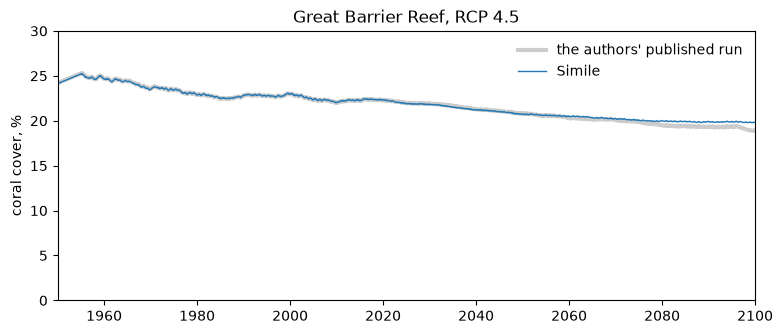

1955-2100: largest difference 1.05 percentage points, mean 0.14


In [3]:
t = time.time()
with Session(MODEL, parameters=params('GBR', 'RCP45'), run_settings=SETTINGS) as s:
    ours = s.run(variables=['coral_cover', 'Trait'])
print(f'{len(ours)} months in {time.time() - t:.1f} s (including compiling the model)')

K_C = params('GBR', 'RCP45')['variables']['K_C']
theirs = pd.Series(np.array(load_theirs(str(THEIRS / 'Results' / 'CORAL-RCP45-GBR.dat'))) / K_C * 100,
                   index=np.arange(25764) - SPINUP)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(1955 + theirs.index / 12, theirs.values, lw=3, color='0.8', label='the authors\' published run')
ax.plot(year(ours), ours['coral_cover'], lw=1, color='C0', label='Simile')
ax.set_xlim(1950, 2100); ax.set_ylim(0, 30); ax.set_ylabel('coral cover, %'); ax.legend(frameon=False)
ax.set_title('Great Barrier Reef, RCP 4.5')
plt.show()
shared = ours.index.intersection(theirs.index)
d = (ours.loc[shared, 'coral_cover'] - theirs.loc[shared]).abs()
print(f'1955-2100: largest difference {d[d.index >= 0].max():.2f} percentage points, mean {d[d.index >= 0].mean():.2f}')

## 2. Calibrating N against observed coral cover (the paper's Fig 2)

The observations are the yearly regional medians the authors used, as given in their `N_estimation-Fig-2.py`: Bruno & Selig (2007) for all three regions, and De'ath et al. (2012) for the Great Barrier Reef. The authors chose N **by eye**, from runs over a range of N. Here we run the same range (from 1 to 10 × 10⁻¹³) and also measure the fit: the root-mean-square difference between the model's yearly coral cover and the observations.

114 runs in 97 s


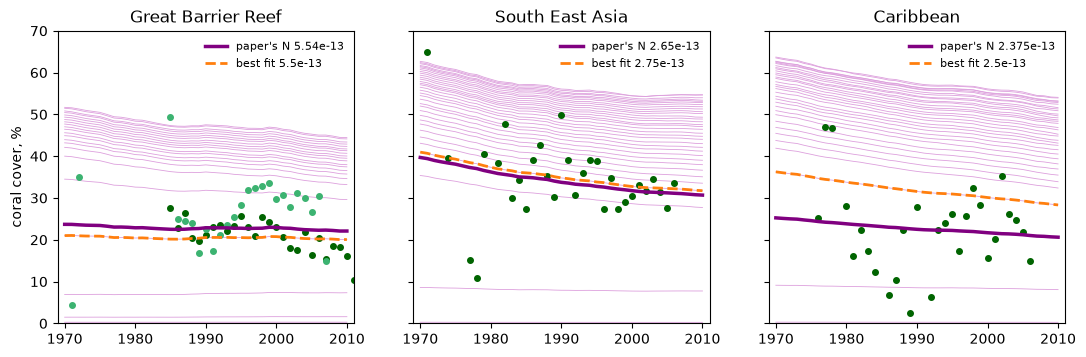

        paper's N    best-fit N  misfit at paper's N  misfit at best fit
GBR  5.540000e-13  5.500000e-13             7.172583            7.768481
SEA  2.650000e-13  2.750000e-13             9.274977            9.266442
CAR  2.375000e-13  2.500000e-13            10.169971           13.689571


In [4]:
OBS = {   # year: percent coral cover (the authors' data, from their N_estimation-Fig-2.py)
 'GBR': [dict(zip(range(1985, 2013), [27.6392, 22.7458, 26.3999, 20.5105, 19.6836, 21.18, 23.0085, 23.4262, 22.184, 23.1825, 25.7579, 23.1051, 20.8673, 25.4344, 24.2754, 23.0333, 20.6293, 17.9764, 17.4814, 21.7995, 16.3249, 20.4771, 15.5005, 18.5738, 18.3276, 16.0067, 10.3663, 9.70535]))   # De'ath et al. 2012
       , dict(zip([1971, 1972] + list(range(1985, 2008)), [4.3, 34.975, 49.375, 24.906481481481478, 24.441163003663007, 24.126298701298698, 16.893939393939394, 22.58467261904762, 17.311111111111114, 21.028985714285714, 23.52760639360639, 25.455069209922868, 28.285919266492023, 31.795480366220563, 32.27244858458291, 32.98251030353662, 33.63890012368584, 29.743189587198515, 30.616005555555553, 27.78740121782979, 31.235181694495974, 30.107761904761908, 26.650676470588238, 30.47691011235955, 14.8554]))],  # Bruno & Selig 2007
 'SEA': [dict(zip([1971, 1974, 1977, 1978, 1979] + list(range(1981, 2007)), [65.0, 39.68333333333334, 15.176470588235293, 10.75, 40.61522988505747, 38.42666666666667, 47.68205128205128, 29.9, 34.22222222222222, 27.421666666666663, 38.97849462365591, 42.78793922127256, 35.26521739130435, 30.22222222222222, 49.857142857142854, 38.98494623655914, 30.64814814814815, 35.90231159420289, 39.0003869047619, 38.7478983974359, 27.335411368015414, 34.82625932835821, 27.322793103448276, 29.01994680851064, 30.41432584269663, 33.062789351851855, 31.652665770609318, 34.652255639097746, 31.402439024390244, 27.543560606060606, 33.60991033755274]))],
 'CAR': [dict(zip([1976, 1977, 1978, 1980, 1981, 1982, 1983, 1984, 1986, 1987, 1988, 1989, 1990, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006], [25.17, 47.1, 46.7735, 28.0875, 16.1, 22.4429375, 17.2, 12.26666667, 6.78571429, 10.296, 22.4, 2.55, 27.85, 6.3375, 22.32375, 24.10105556, 26.1696, 17.36739394, 25.76126312, 32.40814444, 28.30322, 15.62805952, 20.24744444, 35.37140909, 26.1427, 24.74643878, 21.81088542, 14.9610625]))],
}

def yearly(df):
    return df['coral_cover'].groupby(np.floor(year(df)).astype(int)).mean()

def misfit(cover, reg):
    pts = [(y, v) for src in OBS[reg] for y, v in src.items() if y in cover.index]
    return float(np.sqrt(np.mean([(cover[y] - v) ** 2 for y, v in pts])))

N_GRID = np.round(np.arange(1.0, 10.01, 0.25) * 1e-13, 16)
calib, at_paper = {}, {}
t = time.time()
for reg in REGIONS:
    with Session(MODEL, parameters=params(reg, 'RCP26'), run_settings=SETTINGS) as s:
        calib[reg] = {N: yearly(s.run({'N': float(N)}, variables=['coral_cover'])) for N in N_GRID}
        at_paper[reg] = yearly(s.run({'N': N_PAPER[reg]}, variables=['coral_cover']))   # the paper's own N, exactly
print(f'{(len(N_GRID) + 1) * 3} runs in {time.time() - t:.0f} s')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
best = {}
for ax, reg in zip(axes, REGIONS):
    fits = {N: misfit(c, reg) for N, c in calib[reg].items()}
    best[reg] = min(fits, key=fits.get)
    for N, c in calib[reg].items():
        ax.plot(c.loc[1970:2010].index, c.loc[1970:2010].values, color='plum', lw=0.6)
    for src, colour in zip(OBS[reg], ['darkgreen', 'mediumseagreen']):
        ax.plot(list(src), list(src.values()), 'o', ms=4, color=colour)
    ax.plot(at_paper[reg].loc[1970:2010], color='purple', lw=2.5, label=f'paper\'s N {N_PAPER[reg]:.4g}')
    ax.plot(calib[reg][best[reg]].loc[1970:2010], color='C1', lw=2, ls='--', label=f'best fit {best[reg]:.3g}')
    ax.set_title(REGIONS[reg]); ax.set_xlim(1969, 2011); ax.set_ylim(0, 70); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('coral cover, %')
plt.show()
print(pd.DataFrame({'paper\'s N': N_PAPER, 'best-fit N': best,
                    'misfit at paper\'s N': {r: misfit(at_paper[r], r) for r in REGIONS},
                    'misfit at best fit': {r: misfit(calib[r][best[r]], r) for r in REGIONS}}).round(16))

Each thin line is one value of N; the observations are the green dots. Coral cover rises with N, as in the paper's Fig 2, and in places steeply: in the Caribbean it jumps from under 10% to over 30% between N = 2.25 and 2.5 × 10⁻¹³, just where the paper's estimate lies. The misfit is in percentage points of cover. The "best fit" is the best on this grid; where cover changes this steeply with N a grid step of 0.25 × 10⁻¹³ is coarse, and the paper's own N fits as well or better (the Great Barrier Reef, the Caribbean). The authors' estimates by eye hold up.

Two cautions, as the paper itself says: the observations are noisy medians of very uneven samples, and observed cover is a share of the surveyed reef, while the model's is a share of a regional carrying capacity. So a least-squares fit is one defensible choice among several; the authors judged by eye, and partly by the trend.

## 3. Projections to 2100 (the paper's headline numbers)

Coral abundance in 2081-2100 relative to 1986-2005, with the paper's N, under each scenario. Bleaching is random, so each is the mean of five runs (with their range).

In [5]:
PAPER_CHANGE = {('GBR', 'RCP26'): -15, ('GBR', 'RCP45'): -12, ('GBR', 'RCP85'): -18,
                ('SEA', 'RCP26'): -47, ('SEA', 'RCP45'): -55, ('SEA', 'RCP85'): -53,
                ('CAR', 'RCP26'): -42, ('CAR', 'RCP45'): -49, ('CAR', 'RCP85'): -52}   # the paper's Results ("more than" for CAR)

def change(df):
    y = year(df)
    late, early = df['coral_cover'][(y >= 2081) & (y < 2101)].mean(), df['coral_cover'][(y >= 1986) & (y < 2006)].mean()
    return 100 * (late / early - 1)

rows, t = [], time.time()
for reg in REGIONS:
    with Session(MODEL, parameters=params(reg, 'RCP26'), run_settings=SETTINGS) as s:
        for rcp in RCPS:
            forcing = {k: params(reg, rcp)['variables'][k] for k in ('T_data', 'T_spinup')}
            runs = [change(s.run({'N': N_PAPER[reg], **forcing}, variables=['coral_cover'])) for _ in range(5)]
            rows.append({'region': REGIONS[reg], 'scenario': RCPS[rcp], 'paper, %': PAPER_CHANGE[(reg, rcp)],
                         'Simile, mean of 5, %': round(np.mean(runs), 1), 'range, %': f'{min(runs):.0f} to {max(runs):.0f}'})
print(f'45 runs in {time.time() - t:.0f} s')
pd.DataFrame(rows).set_index(['region', 'scenario'])

45 runs in 51 s


paper, %  Simile, mean of 5, %    range, %
region             scenario                                            
Great Barrier Reef RCP 2.6        -15                 -15.1  -16 to -15
                   RCP 4.5        -12                 -11.9  -12 to -12
                   RCP 8.5        -18                 -15.5  -17 to -15
South East Asia    RCP 2.6        -47                 -42.8  -44 to -42
                   RCP 4.5        -55                 -52.9  -53 to -52
                   RCP 8.5        -53                 -52.5  -54 to -52
Caribbean          RCP 2.6        -42                 -40.2  -41 to -39
                   RCP 4.5        -49                 -44.9  -47 to -43
                   RCP 8.5        -52                 -49.4  -50 to -49

## 4. Sensitivity (the paper's Figs 5 and 6)

Mean coral abundance over 2001-2100, scaled by the carrying capacity, over a range of N, with each of ten parameters 25% higher (left) or lower (right) than in Table 1. Here for South East Asia under RCP 4.5; the paper shows all nine regions and scenarios (change `REG` and `RCP` to see another).

Nine of the ten parameters are constants in the model, so each variant is a **copy of the model spec with that constant changed**, compiled once (a few seconds), then run over the range of N. That is the Simile way of asking "what if this constant were different": change the model, not the code.

273 runs, 19 versions of the model, in 274 s; not finished: b x0.75 (from N = 1e-13)


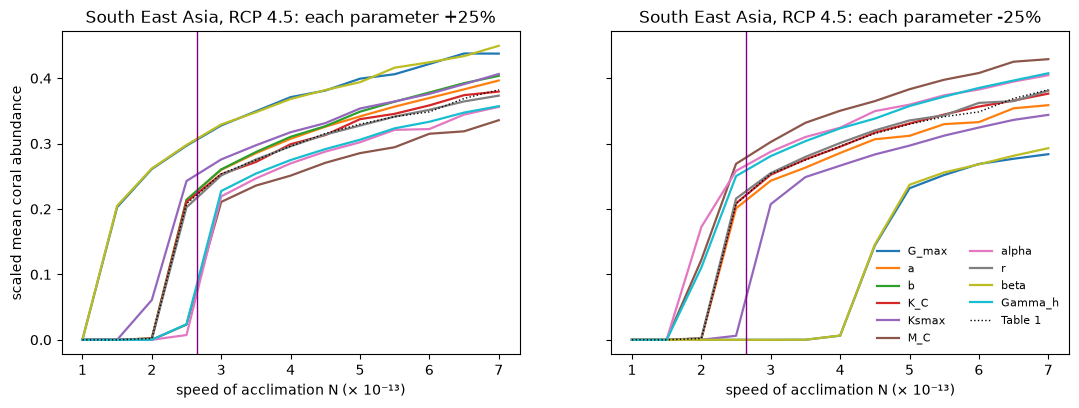

In [6]:
REG, RCP = 'SEA', 'RCP45'
PARAMS = {'G_max': 'G_max', 'a': 'a', 'b': 'b', 'K_C': 'K_C', 'Ksmax': 'Ksmax', 'M_C': 'M_C',
          'alpha': 'alpha', 'r': 'r', 'beta': 'beta', 'Gamma_h': 'gammaH'}     # paper's name: the model's
N_SENS = np.round(np.arange(1.0, 7.01, 0.5) * 1e-13, 16)

def with_constant(spec, label, factor):
    out = json.loads(json.dumps(spec))
    node = next(n for n in out['nodes'].values() if n['label'] == label)
    node['props']['value'] = repr(float(node['props']['value']) * factor)
    return out

def mean_cover(df):                         # 2001-2100, as a fraction of carrying capacity
    return df['coral_cover'][year(df) >= 2001].mean() / 100

# A run that does not finish in 30 s is recorded as missing, and the rest of
# that version skipped: the engine can stall when a value sinks towards the
# smallest number a computer holds (here, b -25%: the symbionts die out late
# in the century). Recorded for Simile's developers.
sens, unfinished, t = {}, [], time.time()
s = Session(MODEL, parameters=params(REG, RCP), run_settings=SETTINGS, time_limit=30)
def sweep(name, model, extra=None):
    global s
    out = []
    for N in N_SENS:
        try:
            out.append(mean_cover(s.run({'N': float(N), **(extra or {})}, variables=['coral_cover'], model=model)))
        except SimileError:
            unfinished.append(f'{name} (from N = {N:g})')
            s.close(); s = Session(MODEL, parameters=params(REG, RCP), run_settings=SETTINGS, time_limit=30)
            return out + [np.nan] * (len(N_SENS) - len(out))
    return out
sens['Table 1'] = sweep('Table 1', MODEL)
for factor in (1.25, 0.75):
    for name, label in PARAMS.items():
        if label == 'K_C':              # a regional parameter: changed in the run's values
            sens[(name, factor)] = sweep(f'{name} x{factor}', MODEL, {'K_C': params(REG, RCP)['variables']['K_C'] * factor})
        else:                           # a constant: a changed copy of the model
            sens[(name, factor)] = sweep(f'{name} x{factor}', with_constant(MODEL, label, factor))
s.close()
print(f'{len(sens) * len(N_SENS)} runs, 19 versions of the model, in {time.time() - t:.0f} s;',
      'not finished: ' + ', '.join(unfinished) if unfinished else 'all finished')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, factor, title in zip(axes, (1.25, 0.75), ('+25%', '-25%')):
    for i, name in enumerate(PARAMS):
        ax.plot(N_SENS * 1e13, sens[(name, factor)], lw=1.6, color=plt.cm.tab10(i), label=name)
    ax.plot(N_SENS * 1e13, sens['Table 1'], color='k', lw=1, ls=':', label='Table 1')
    ax.axvline(N_PAPER[REG] * 1e13, color='purple', lw=1)
    ax.set_title(f'{REGIONS[REG]}, {RCPS[RCP]}: each parameter {title}')
    ax.set_xlabel('speed of acclimation N (× 10⁻¹³)')
axes[0].set_ylabel('scaled mean coral abundance'); axes[1].legend(frameon=False, fontsize=8, ncol=2)
plt.show()

As in the paper, coral abundance rises with the speed of acclimation whichever parameter is changed; single runs carry some noise from the random bleaching.

**One gap: `b` −25% (right).** With the symbionts' growth that much slower, they can die out late in the century, and somewhere below 10⁻⁶³ cells Simile's engine stops returning; so that curve stops where a run first did not finish (printed above). It is a fault in the engine, not the model (the authors' solver carries on), recorded for Simile's developers. It also shows why each run has a time limit.

## What this shows

- **The model stays a diagram.** Nothing above restates its equations; every run is Simile's own, from `coral.json`.
- **The analysis is the researcher's own Python**: loops, fitting, tables and plots, as in any notebook.
- **Changing a constant is changing the model**, as a copy of its spec, rather than editing code.

This notebook drives a hidden browser on the same machine. Before it can be shared as a link, the model needs to run where the notebook does: the app's engine as a notebook widget (JupyterLite, Colab), or a Python package that compiles Simile models natively, which would also suit large models and long batches of runs.